## Setup and policy parameters

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cwfc.data import load_cpu, build_targets, split_train_holdout
from cwfc.models import damped_persistence_forecast
from cwfc.validation import rolling_origin_forecasts
from cwfc.policy import headroom, interval_offsets, apply_band, coverage, alert_rates

cpu = load_cpu("../challenge_data/vm_cpu_readings.csv.gz")
targets = build_targets(cpu)
train, holdout = split_train_holdout(targets)
pred = pd.read_csv("../predictions.csv")
t = "aggregate_cpu_utilization"

HEADROOM_LEVEL = 0.90      # fixed before looking at the holdout
INTERVAL_LEVEL = 0.90
high_load_level = train[t].quantile(0.90)
print("high-load level:", round(high_load_level, 3))

high-load level: 9.668


**What this shows:** The high-load level is 9.668%, the 90th percentile of the training series, the same definition used for peaks earlier. Headroom and band levels are fixed at 90% before any holdout value is used.

## Validation forecast errors

In [2]:
val = rolling_origin_forecasts(train, t, damped_persistence_forecast)
val["error"] = val["actual"] - val["pred"]          # positive = forecast too low
val["block"] = pd.cut(val["step"], [0, 6, 12, 18, 24],
                      labels=["1-6", "7-12", "13-18", "19-24"])
print(val["error"].describe().round(3))
print(val.groupby("block", observed=True)["error"].quantile([0.05, 0.5, 0.95]).unstack().round(3))

count    168.000
mean       0.007
std        0.243
min       -0.362
25%       -0.172
50%       -0.065
75%        0.193
max        0.526
Name: error, dtype: float64
        0.05   0.50   0.95
block                     
1-6   -0.263  0.013  0.465
7-12  -0.309 -0.038  0.502
13-18 -0.301 -0.086  0.429
19-24 -0.343 -0.135  0.282


**What this shows:** Over the 168 validation forecasts (7 origins × 24 steps) the mean error is 0.007 points, so the final model is not biased on average, and the spread is 0.243 points. The error does not grow with the forecast step: the 95th percentile is 0.465, 0.502, 0.429 and 0.282 across the four 30-minute blocks, so a single margin is used. The median error falls from +0.013 to −0.135 across the blocks, so in validation the forecast tends to be too high at later steps. The holdout showed the opposite timing (too high early, close at the end), so this pattern should not be treated as stable across windows.

## Headroom and forecast band

In [3]:
h = headroom(val["actual"], val["pred"], HEADROOM_LEVEL)
lo, hi = interval_offsets(val["actual"], val["pred"], INTERVAL_LEVEL)
print("headroom:", round(h, 3))
print("90% band offsets:", round(lo, 3), round(hi, 3))
print("validation coverage of band:",
      round(coverage(val["actual"], val["pred"] + lo, val["pred"] + hi), 3))

headroom: 0.409
90% band offsets: -0.335 0.456
validation coverage of band: 0.893


**What this shows:** The 90% headroom is 0.409 percentage points, about 4.3% of the average level (9.41%), so the extra capacity is small. The 90% band is the forecast minus 0.335 to plus 0.456 points and contains 89.3% of validation points. This coverage is close to 90% by construction because the band was fitted on these same errors; the holdout is the out-of-sample check. The margins come from only 7 overlapping origins, so they are approximate.

## Trade-off between headroom and alerts (validation)

In [4]:
rows = []
for level in [0.50, 0.80, 0.90, 0.95]:
    hh = headroom(val["actual"], val["pred"], level)
    r = alert_rates(val["actual"], val["pred"] + hh, high_load_level)
    rows.append({"level": level, "headroom": hh, **r})
print(pd.DataFrame(rows).round(3))

   level  headroom  events  normal_points  hit_rate  false_alarm_rate
0   0.50     0.000      30            138     0.000             0.014
1   0.80     0.250      30            138     0.267             0.804
2   0.90     0.409      30            138     1.000             1.000
3   0.95     0.456      30            138     1.000             1.000


**What this shows:** An alert that fires when forecast plus headroom reaches the high-load level does not separate peaks from normal periods. With 80% headroom the alert fires at 27% of real high-load points but 80% of normal points, so it is more likely during normal periods than during peaks. With 90% or 95% headroom it fires at every point (hit rate and false-alarm rate both 100%). The reason is that the peak is only about 0.5 points high, similar in size to the forecast error and to the headroom, and the forecast does not anticipate it. A threshold alert on the aggregate level is therefore not recommended.

## Holdout check

In [5]:
assert pred["timestamp"].tolist() == holdout["timestamp"].tolist()
final = pred[t].to_numpy()
actual = holdout[t].to_numpy()

lower, upper = apply_band(final, lo, hi)
planned = np.clip(final + h, 0, 100)      # forecast + headroom

print("band coverage on holdout:", round(coverage(actual, lower, upper), 3))
print("share of points at or below planned level:", round(float((actual <= planned).mean()), 3))
print("mean band width:", round(float((upper - lower).mean()), 3))
print(alert_rates(actual, planned, high_load_level))
outside = np.where((actual < lower) | (actual > upper))[0]
print("steps outside the band:", outside + 1)
print("all below the lower edge:", bool((actual[outside] < lower[outside]).all()))

band coverage on holdout: 0.958
share of points at or below planned level: 1.0
mean band width: 0.79
{'events': 0, 'normal_points': 24, 'hit_rate': nan, 'false_alarm_rate': 0.9583333333333334}
steps outside the band: [6]
all below the lower edge: True


**What this shows:** On the 24 holdout points the 90% band contained 95.8% of actual values (23 of 24); the one point outside is below the lower edge. Actual load never exceeded forecast plus headroom (24 of 24 points at or below it), so the policy would not have under-provisioned. The band is 0.79 points wide on average. No holdout point reaches the high-load level, so the hit rate is undefined, while the alert rule would still have fired at 23 of 24 normal points (false-alarm rate 95.8%), which confirms the validation finding. Because the holdout has no peak and the forecast was above the actual value for most of the window, it tests the cost of over-provisioning more than the risk of under-provisioning.

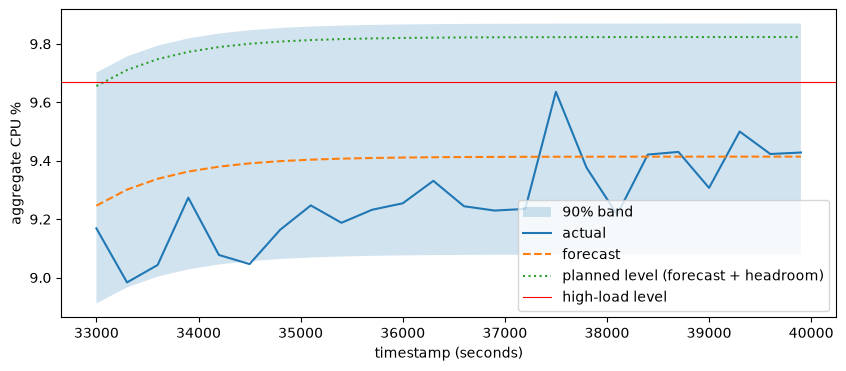

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(holdout["timestamp"], lower, upper, alpha=0.2, label="90% band")
ax.plot(holdout["timestamp"], actual, label="actual")
ax.plot(holdout["timestamp"], final, linestyle="--", label="forecast")
ax.plot(holdout["timestamp"], planned, linestyle=":", label="planned level (forecast + headroom)")
ax.axhline(high_load_level, color="red", linewidth=0.8, label="high-load level")
ax.set_xlabel("timestamp (seconds)")
ax.set_ylabel("aggregate CPU %")
ax.legend()
plt.show()

**What this shows:** The forecast lies above the actual load for most of the window, the actual load stays inside the 90% band except for one point at the lower edge, and the planned level (forecast plus headroom) is above the high-load line for almost the whole window.

## Cost of the policy (spare capacity)

In [7]:
spare = planned - actual
print("mean spare capacity:", round(float(spare.mean()), 3))
print("minimum spare capacity:", round(float(spare.min()), 3))
print("mean spare as share of average level:", round(float(spare.mean() / train[t].mean()), 3))

mean spare capacity: 0.533
minimum spare capacity: 0.187
mean spare as share of average level: 0.057


**What this shows:** The planned level left on average 0.533 points of spare capacity (about 5.7% of the average level) and never fewer than 0.187 points. This is the price of the policy on a calm window: it avoided under-provisioning but held more capacity than was used.

## Recommended policy

1. **Plan for forecast plus headroom.** Provision for the forecast plus 0.41 percentage points of aggregate CPU, the 90th percentile of validation under-forecast errors. This is about 4.3% of the typical level. Because the aggregate is a mean over about 10,000 VMs, 0.41 points corresponds roughly to the CPU of 41 fully used average VMs (VMs differ in size, so this is only a rough unit). On the holdout, the planned level was never exceeded.
2. **Report the 90% band, not only a point forecast.** The band is the forecast minus 0.34 to plus 0.46 points. It covered 89.3% of validation points and 95.8% of holdout points. It is based on past errors and is not a guarantee.
3. **Do not use a threshold alert on the aggregate level.** The trade-off table shows that such an alert does not separate peaks from normal periods (27% hits against 80% false alarms at 80% headroom; 100% against 100% at 90%), and on the holdout it fired at 23 of 24 normal points.
4. **Watch the busiest VMs directly.** The aggregate hides concentrated load: the busiest 1% of VMs carry 9.6% of total CPU and the 99th percentile of VM average CPU is 79.6%. Capacity decisions that matter for performance should include a rule on these VMs, which this dataset cannot forecast reliably at the aggregate level.
5. **Review regularly.** Recompute the headroom as new data arrives and widen it if recent forecast errors grow.

**Trade-off.** More headroom lowers the chance of under-provisioning (performance or availability risk) but raises idle capacity and, for alerts, false alarms. With about 11 hours of data, an aggregate forecast and no information on real capacity limits, this policy is a guide for planning, not a production autoscaler.